#### Forecast experiment 1 - Sine wave, version 2
This version uses actual train/val/test -split for data + TensorFlow datasets instead of the deprecated generators.


In [49]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn import metrics
from sklearn.metrics import mean_absolute_percentage_error
import keras
import seaborn as sns

# in time series forecasting, we usually need to scale our values
# for better end results
from sklearn.preprocessing import MinMaxScaler

# lock down the random seed, to ensure reproducibility of results
# seed = 2026
seed = 91
keras.utils.set_random_seed(seed)

In [50]:
# Load the Dataset
df = pd.read_csv("electricityConsumptionAndProductioction.csv")


In [51]:
df

,DateTime,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
0,2019-01-01 00:00:00,6352,6527,1395,79,1383,1896,1744,0,30
1,2019-01-01 01:00:00,6116,5701,1393,96,1112,1429,1641,0,30
2,2019-01-01 02:00:00,5873,5676,1393,142,1030,1465,1616,0,30
3,2019-01-01 03:00:00,5682,5603,1397,191,972,1455,1558,0,30
4,2019-01-01 04:00:00,5557,5454,1393,159,960,1454,1458,0,30
...,...,...,...,...,...,...,...,...,...,...
62805,2026-03-14 19:00:00,7132,6937,1339,699,2560,1590,598,0,59
62806,2026-03-14 20:00:00,7027,6827,1339,744,2538,1571,579,0,58
62807,2026-03-14 21:00:00,6615,6612,1341,778,2291,1569,578,0,60
62808,2026-03-14 22:00:00,6063,6421,1335,701,2146,1556,586,0,61


In [52]:
# for easier and more dynamic code, save the value column name here
value_column = 'Consumption'

#### Before going any further, scale the values in our DataFrame

In [53]:
# scale the values with MinMaxScaler so that we don't
# affect the distribution of data (thus making the signal not realistic anymore)
# MinMaxScaler is a good solution here
scaler = MinMaxScaler()
df[[value_column]] = scaler.fit_transform(df[[value_column]])

# as weird as it sounds, scaling the index/sequence number also
# to be a decimal might affect the performance of the network
df = df.drop("DateTime", axis=1)
# df.index = df.index * 0.1 + 1

In [54]:
df

,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
0,0.403431,6527,1395,79,1383,1896,1744,0,30
1,0.378441,5701,1393,96,1112,1429,1641,0,30
2,0.352711,5676,1393,142,1030,1465,1616,0,30
3,0.332486,5603,1397,191,972,1455,1558,0,30
4,0.319250,5454,1393,159,960,1454,1458,0,30
...,...,...,...,...,...,...,...,...,...
62805,0.486023,6937,1339,699,2560,1590,598,0,59
62806,0.474905,6827,1339,744,2538,1571,579,0,58
62807,0.431279,6612,1341,778,2291,1569,578,0,60
62808,0.372829,6421,1335,701,2146,1556,586,0,61


In [55]:
# let's figure out a good cutoff point for train/test
# 80% for training, 20% testing (NOTE: you should experiment on this to find optimal %)
cutoff = int(len(df) * 0.8)

# train data
X_train = df.index[0:cutoff]
y_train = df[value_column].iloc[0:cutoff]

# test data
X_test = df.index[cutoff:]
y_test = df[value_column].iloc[cutoff:]

# convert everything into NumPy -array format
X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

# in this case, number of variables is 1 => scaled passengers value
n_features = 1

# use reshape tools to get the data ready for future use
train_series = y_train.reshape((len(y_train), n_features))
test_series  = y_test.reshape((len(y_test), n_features))

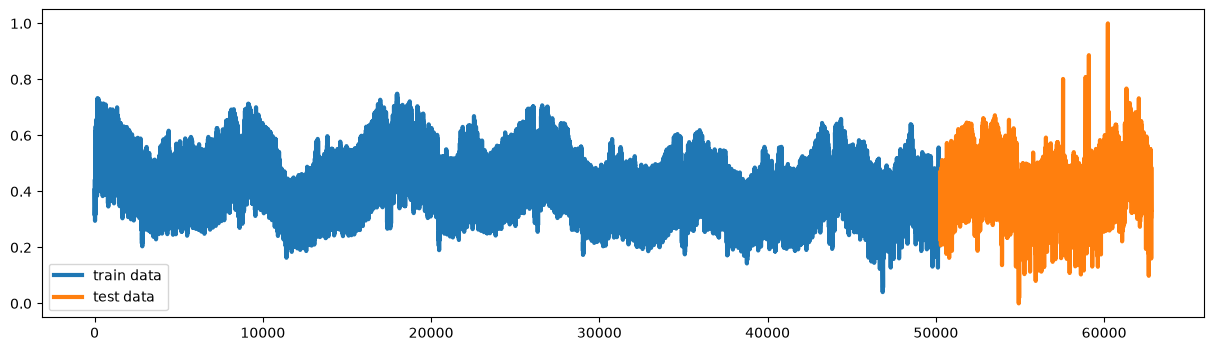

In [56]:
fig, ax = plt.subplots(1, 1, figsize=(15, 4))
ax.plot(X_train,y_train, lw=3, label='train data')
ax.plot(X_test, y_test,  lw=3, label='test data')
ax.legend(loc="lower left")
plt.show()

#### Train/test datasets with generators

In [57]:
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator

# the variable that determines how many points
# back into the past the model attempts to learn
look_back  = 16
batch_size = 1

# stride = 1 => means we use separate time steps
# more than 1 => we use windowing

# TimeseriesGenerators were deprecated by TensorFlow developers
# during October 2024
# this means, in some unknown future TensorFlow -version
# this feature will removed
# check the other version of this notebook on how to replace
# TimeseriesGenerator with a TensorFlow Dataset
train_generator = TimeseriesGenerator(train_series, train_series,
                                      length        = look_back, 
                                      sampling_rate = 1,
                                      stride        = 1,
                                      batch_size    = batch_size)

test_generator = TimeseriesGenerator(test_series, test_series,
                                      length        = look_back, 
                                      sampling_rate = 1,
                                      stride        = 1,
                                      batch_size    = batch_size)

#### Create neural network

In [ ]:
from keras.models import Sequential
from keras import Input
from keras.layers import LSTM, SimpleRNN
from keras.layers import Dense
from keras.callbacks import ModelCheckpoint

# create a model checkpoint to a file, and only save the best one
mc = ModelCheckpoint('best_model_electricity_price.keras', monitor='val_loss', mode='min', save_best_only=True)
callback_list = [mc]

# build the neural network
# in this case, LSTM with 8 neurons
n_neurons  = 64

model = Sequential()
model.add(Input(shape=(look_back, n_features)))
model.add(LSTM(n_neurons, activation="relu"))
model.add(Dense(16, activation="relu"))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')

initial_weights = model.get_weights()

# it's not optimal to use test data as validation data
# because this might skew our metrics
# see the other version of this notebook on how to do
# train/validation/test -split for the sine wave
model.fit(train_generator, epochs=50, verbose=1, validation_data=test_generator, callbacks=callback_list)

Epoch 1/50
 2334/50232 ━━━━━━━━━━━━━━━━━━━━ 1:26 2ms/step - loss: 0.0085

#### Training metrics

In [ ]:
# the usual training metrics visualization
loss_df = pd.DataFrame(model.history.history)
loss_df.plot()

AttributeError: 'Sequential' object has no attribute 'history'

In [ ]:
# reload the best version of the model
from keras.models import load_model
model = load_model("best_model_electricity_price.keras")

In [ ]:
# TensorFlow evaluation metrics
result = model.evaluate(train_generator)
print(f"Training loss: {result}")

# test loss
result = model.evaluate(test_generator)
print(f"Testing loss: {result}")

# these values are not very close to each other, 
# which means my model is not quite optimal
# IN THEORY 

1568/1568 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - loss: 3.4684e-04
Training loss: 0.0003468430077191442
390/390 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 5.7413e-04
Testing loss: 0.0005741330096498132


#### Test predictions

In [ ]:
test_predictions  = model.predict(test_generator)

390/390 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


#### Conventional regression metrics + MAPE

In [ ]:
# let's make a separate copy of the test values
# so we can calculate some errors

actual_y_test = np.concatenate([y for x, y in test_generator])
errors = np.abs(actual_y_test - test_predictions)
mape = mean_absolute_percentage_error(actual_y_test, test_predictions) * 100

# print out the MAPE-score
print("MAPE (mean average precision error):")
print(f"{round(mape, 2)} %")

# MAE - Mean average error
print("\nMAE")
print(round(metrics.mean_absolute_error(actual_y_test, test_predictions), 2), "units")

# MSE - Mean square error
print("\nMSE")
print(round(metrics.mean_squared_error(actual_y_test, test_predictions), 2), "units^2")

# RMSE - Root mean square error
print('\nRMSE:')
print(round(np.sqrt(metrics.mean_squared_error(actual_y_test, test_predictions)), 2), "units")

# R-squared. 0 = the model descibes the dataset poorly
# 1 = model describes the dataset perfectly
print('\nR-squared:')
print(round(metrics.r2_score(actual_y_test, test_predictions), 2))

MAPE (mean average precision error):
134686930452.85 %

MAE
0.02 units

MSE
0.0 units^2

RMSE:
0.02 units

R-squared:
0.96


In [ ]:
# back to real units (MW) so the scaled minimum of 0 no longer breaks MAPE
actual_real = scaler.inverse_transform(actual_y_test.reshape(-1, 1))
pred_real   = scaler.inverse_transform(test_predictions.reshape(-1, 1))

mape  = mean_absolute_percentage_error(actual_real, pred_real) * 100
mae   = metrics.mean_absolute_error(actual_real, pred_real)
mse   = metrics.mean_squared_error(actual_real, pred_real)
rmse  = np.sqrt(mse)
r2    = metrics.r2_score(actual_real, pred_real)

print(f"MAPE: {mape:.2f} %")
print(f"MAE:  {mae:.1f} MW")
print(f"MSE:  {mse:.1f} MW^2")
print(f"RMSE: {rmse:.1f} MW")
print(f"R2:   {r2:.3f}")

MAPE: 2.31 %
MAE:  150.2 MW
MSE:  51206.4 MW^2
RMSE: 226.3 MW
R2:   0.957


#### Compare predictions to test signal, how close they are?

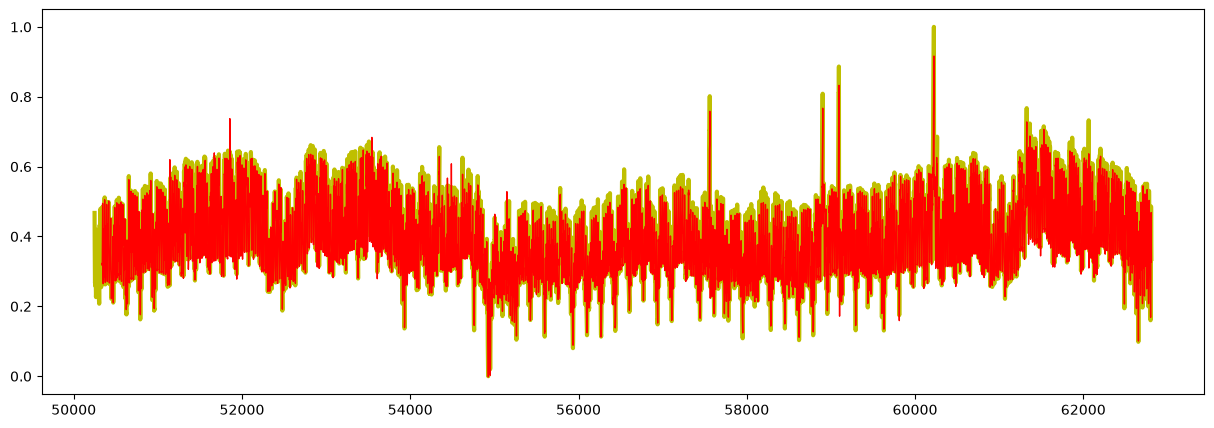

In [ ]:
# calculate helper x-variables for where the train data starts
# where the test data starts and where the predictions start
x1 = np.arange(0, len(y_train))
x2 = np.arange(len(y_train), len(y_train) + len(y_test))
x3 = np.arange(len(y_train) + look_back, len(y_train) + len(y_test))

fig, ax = plt.subplots(1, 1, figsize=(15, 5))
# ax.plot(x1, y_train, lw=2, label='train data')
ax.plot(x2, y_test, lw=3, c='y', label='test data')
ax.plot(x3, test_predictions, lw=1, c='r', label='predictions')
# ax.legend(loc="lower left")
plt.show()

In [ ]:
# TensorFlow evaluation metrics
result = model.evaluate(train_generator)
print(f"Training loss: {result}")

# test loss
result = model.evaluate(test_generator)
print(f"Testing loss: {result}")

# some difference here which we can see in the test-signal prediction already 

1568/1568 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - loss: 3.4684e-04
Training loss: 0.0003468430077191442
390/390 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 5.7413e-04
Testing loss: 0.0005741330096498132


#### Extrapolation into the future

In [ ]:
# EXTRAPOLATION TEST 1 - 120 new points
extrapolation = list()
seed_batch    = y_test[:look_back].reshape((1,look_back, n_features))
current_batch = seed_batch

# extrapolate the next 180 values
for i in range(120):
    predicted_value = model.predict(current_batch, verbose=None)[0]
    extrapolation.append(predicted_value) 
    current_batch = np.append(current_batch[:,1:,:],[[predicted_value]],axis=1)

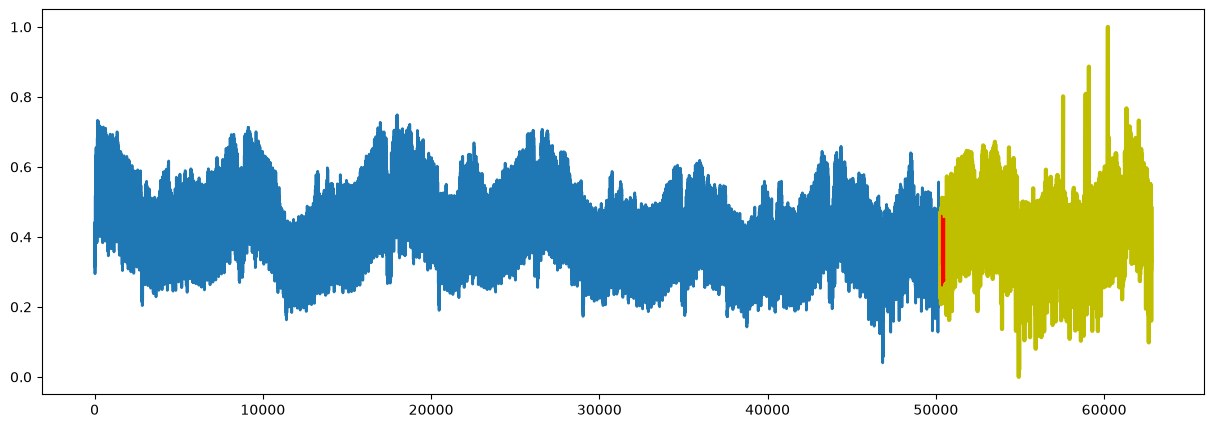

In [ ]:
x1 = np.arange(0, len(y_train))
x2 = np.arange(len(y_train), len(y_train) + len(y_test))
x3 = np.arange(len(y_train) + look_back, len(y_train) + len(extrapolation) + look_back)

fig, ax = plt.subplots(1, 1, figsize=(15, 5))
ax.plot(x1, y_train, lw=2, label='train data')
ax.plot(x2, y_test, lw=3, c='y', label='test data')
ax.plot(x3, extrapolation, lw=1, c='r', label='predictions')
# ax.legend(loc="lower left")
plt.show()

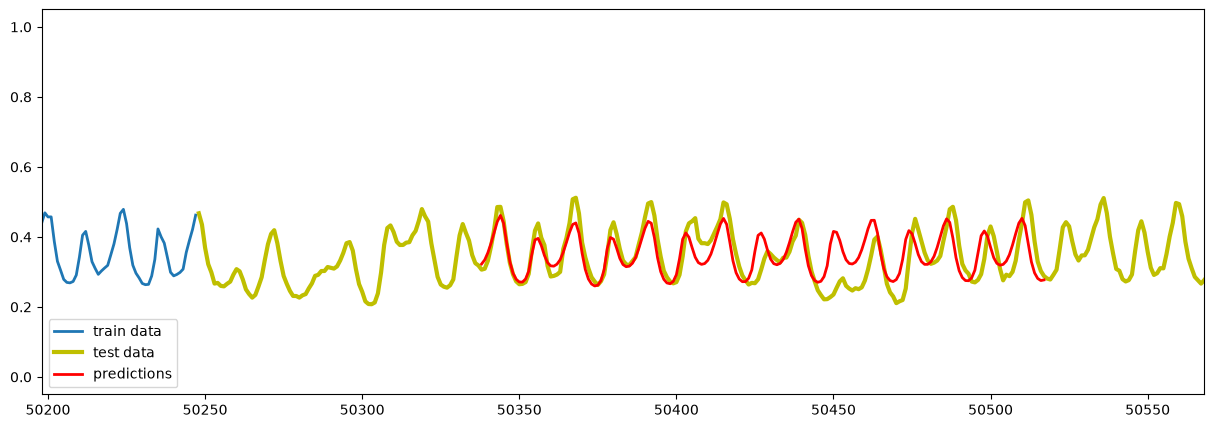

In [ ]:
x1 = np.arange(0, len(y_train))
x2 = np.arange(len(y_train), len(y_train) + len(y_test))
x3 = np.arange(len(y_train) + look_back, len(y_train) + len(extrapolation) + look_back)

fig, ax = plt.subplots(1, 1, figsize=(15, 5))
ax.plot(x1, y_train, lw=2, label='train data')
ax.plot(x2, y_test, lw=3, c='y', label='test data')
ax.plot(x3, extrapolation, lw=2, c='r', label='predictions')

# zoom on the forecast region
ax.set_xlim(len(y_train) - 50, len(y_train) + look_back + len(extrapolation) + 50)
ax.legend(loc="lower left")
plt.show()

#### Step 6: Does the forecast look realistic?

No. In the extrapolation plot the red line is almost flat at about 0.45, while the real gold price moves up and down. Each new prediction is fed back in as input, so the model reads its own smooth guesses instead of real data. Small errors pile up, and the forecast settles on one "typical" value and stays there. The further it goes, the less it tells anything.

#### Step 7: Analysis

The dataset has daily prices for SPX, GLD, USO, SLV and EUR/USD. I forecast GLD (gold). 210 of the 2500 rows were synthetic data at the end of the file, and they ruined my first results (R² below zero), so I removed them with df.iloc[:2290].

The network is an LSTM with 64 units, a Dense layer with 16 units, Dropout 0.2, and a Dense(1) output. It uses Adam and MSE, and ModelCheckpoint saves the epoch with the lowest validation loss. With activation="relu` in the LSTM my training collapsed (the loss went up and stayed flat), and removing it fixed that.

Both losses fall quickly and stay low. MAPE is 3.4% and R² is 0.8, so the predictions follow the real price quite well. The red line is smoother than the real one and misses the highest peaks and lowest dips. The training loss (0.020) is much higher than the test loss (0.00036), so the two are not "very close"

It becomes a flat line, as described above, so the model is useful for one step ahead but not for long-term forecasting.


**Limitations.** The model only knows past values, not news or other causes. Forecast errors grow with the horizon. Financial prices are close to random, so they are hard to predict.

**Optimizations.** May be I have to Try different look_back, number of neurons and split percentages, one at a time. 